# PathSnap Model Training & Benchmark: Multi-Layer Perceptron (Neural Network)
**Course:** UE24CS352A - Machine Learning (PES University)  
**Team 6:** PathSnap Distributed Map-Matching  
**Model Name:** `mlp`  

---
### Notebook Objectives
1. Inspect hyperparameters, training pipeline, and environment provenance.
2. Review 5-fold group-aware cross-validation on 80 training trips (16 trips/fold).
3. Evaluate held-out generalization on the 10 student-test trips.
4. Verify observation-level Top-1 accuracy, Macro F1, and categorical log loss.


In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, HTML, Image

PROJ_ROOT = Path("..").resolve()
MODEL_DIR = PROJ_ROOT / "results" / "run_01" / "mlp"
sys.path.insert(0, str(PROJ_ROOT / "scripts"))

print("Model output directory:", MODEL_DIR)


Model output directory: C:\Users\joshwin\PESU\3RD YEAR\5th sem\ML\team_6\results\run_01\mlp


## 1. Model Configuration & Provenance
Inspection of hyperparameters, random seeds, and package dependencies.


In [2]:
with open(MODEL_DIR / "configuration.json") as f:
    config = json.load(f)
with open(MODEL_DIR / "provenance.json") as f:
    prov = json.load(f)

print(f"Algorithm: {prov['model']} (Random Seed: {prov['seed']})")
print(f"Scikit-Learn Version: {prov['sklearn']} | Python: {prov['python']}")
print("\nKey Parameters:")
for k in sorted(config.keys())[:12]:
    print(f"  {k}: {config[k]}")


Algorithm: mlp (Random Seed: 212)
Scikit-Learn Version: 1.9.1 | Python: 3.12.6

Key Parameters:
  memory: None
  mlpclassifier: MLPClassifier(batch_size=2048, hidden_layer_sizes=(64, 32), max_iter=40,
              random_state=212)
  mlpclassifier__activation: relu
  mlpclassifier__alpha: 0.0001
  mlpclassifier__batch_size: 2048
  mlpclassifier__beta_1: 0.9
  mlpclassifier__beta_2: 0.999
  mlpclassifier__early_stopping: False
  mlpclassifier__epsilon: 1e-08
  mlpclassifier__hidden_layer_sizes: [64, 32]
  mlpclassifier__learning_rate: constant
  mlpclassifier__learning_rate_init: 0.001


## 2. 5-Fold Cross-Validation & Student-Test Evaluation
Group-aware 5-fold evaluation across all 80 training trips, followed by refitting on the full training set and testing on the 10 student-test trips.


In [3]:
with open(MODEL_DIR / "metrics.json") as f:
    records = json.load(f)

rows = []
for r in records:
    m = r["metrics"]["all_points"]
    rel = r["metrics"]["reliable_points"]
    rows.append({
        "Split": r["split"],
        "Top-1 Accuracy": f"{m['top1_accuracy']*100:.2f}%",
        "Macro F1": f"{m['macro_f1']:.4f}",
        "Macro Precision": f"{m['macro_precision']:.4f}",
        "Macro Recall": f"{m['macro_recall']:.4f}",
        "Log Loss": f"{m['categorical_log_loss_with_miss_state']:.4f}",
        "Reliable Top-1": f"{rel['top1_accuracy']*100:.2f}%",
        "Fit Time (s)": f"{r['fit_seconds']:.1f}s",
        "Inf Time (ms)": f"{r['inference_seconds']*1000:.1f}ms"
    })

df_metrics = pd.DataFrame(rows)
display(df_metrics)


,Split,Top-1 Accuracy,Macro F1,Macro Precision,Macro Recall,Log Loss,Reliable Top-1,Fit Time (s),Inf Time (ms)
0,fold_0,77.13%,0.5965,0.6388,0.5783,0.9429,86.47%,83.2s,75.8ms
1,fold_1,75.71%,0.6960,0.7273,0.6817,3.1509,88.07%,75.0s,129.4ms
2,fold_2,46.96%,0.5908,0.6347,0.5703,8.6816,82.12%,85.8s,136.8ms
3,fold_3,74.55%,0.6537,0.6959,0.6325,0.7593,77.45%,65.1s,129.2ms
4,fold_4,85.36%,0.7162,0.7482,0.7035,0.5871,91.70%,198.2s,62.6ms
5,student_test,80.50%,0.6271,0.6705,0.6094,0.6486,88.80%,242.3s,230.2ms


## 3. Performance Summary
Mean cross-validation metrics across all 5 folds.


In [4]:
with open(MODEL_DIR / "summary.json") as f:
    summary = json.load(f)

print(f"Completed Folds: {summary['completed_folds']}")
print(f"Mean CV Macro F1: {summary['cv_macro_f1_mean']:.4f} ± {summary['cv_macro_f1_std']:.4f}")
print(f"Mean CV Top-1 Accuracy: {summary['cv_top1_acc_mean']*100:.2f}%")
print(f"Student-Test Evaluation Complete: {summary['student_test_completed']}")


Completed Folds: 5


Mean CV Macro F1: 0.6506 ± 0.0508
Mean CV Top-1 Accuracy: 71.94%
Student-Test Evaluation Complete: True


## 4. Authentic Epoch-Wise Training History
Visualizing the actual training loss recorded during backpropagation.


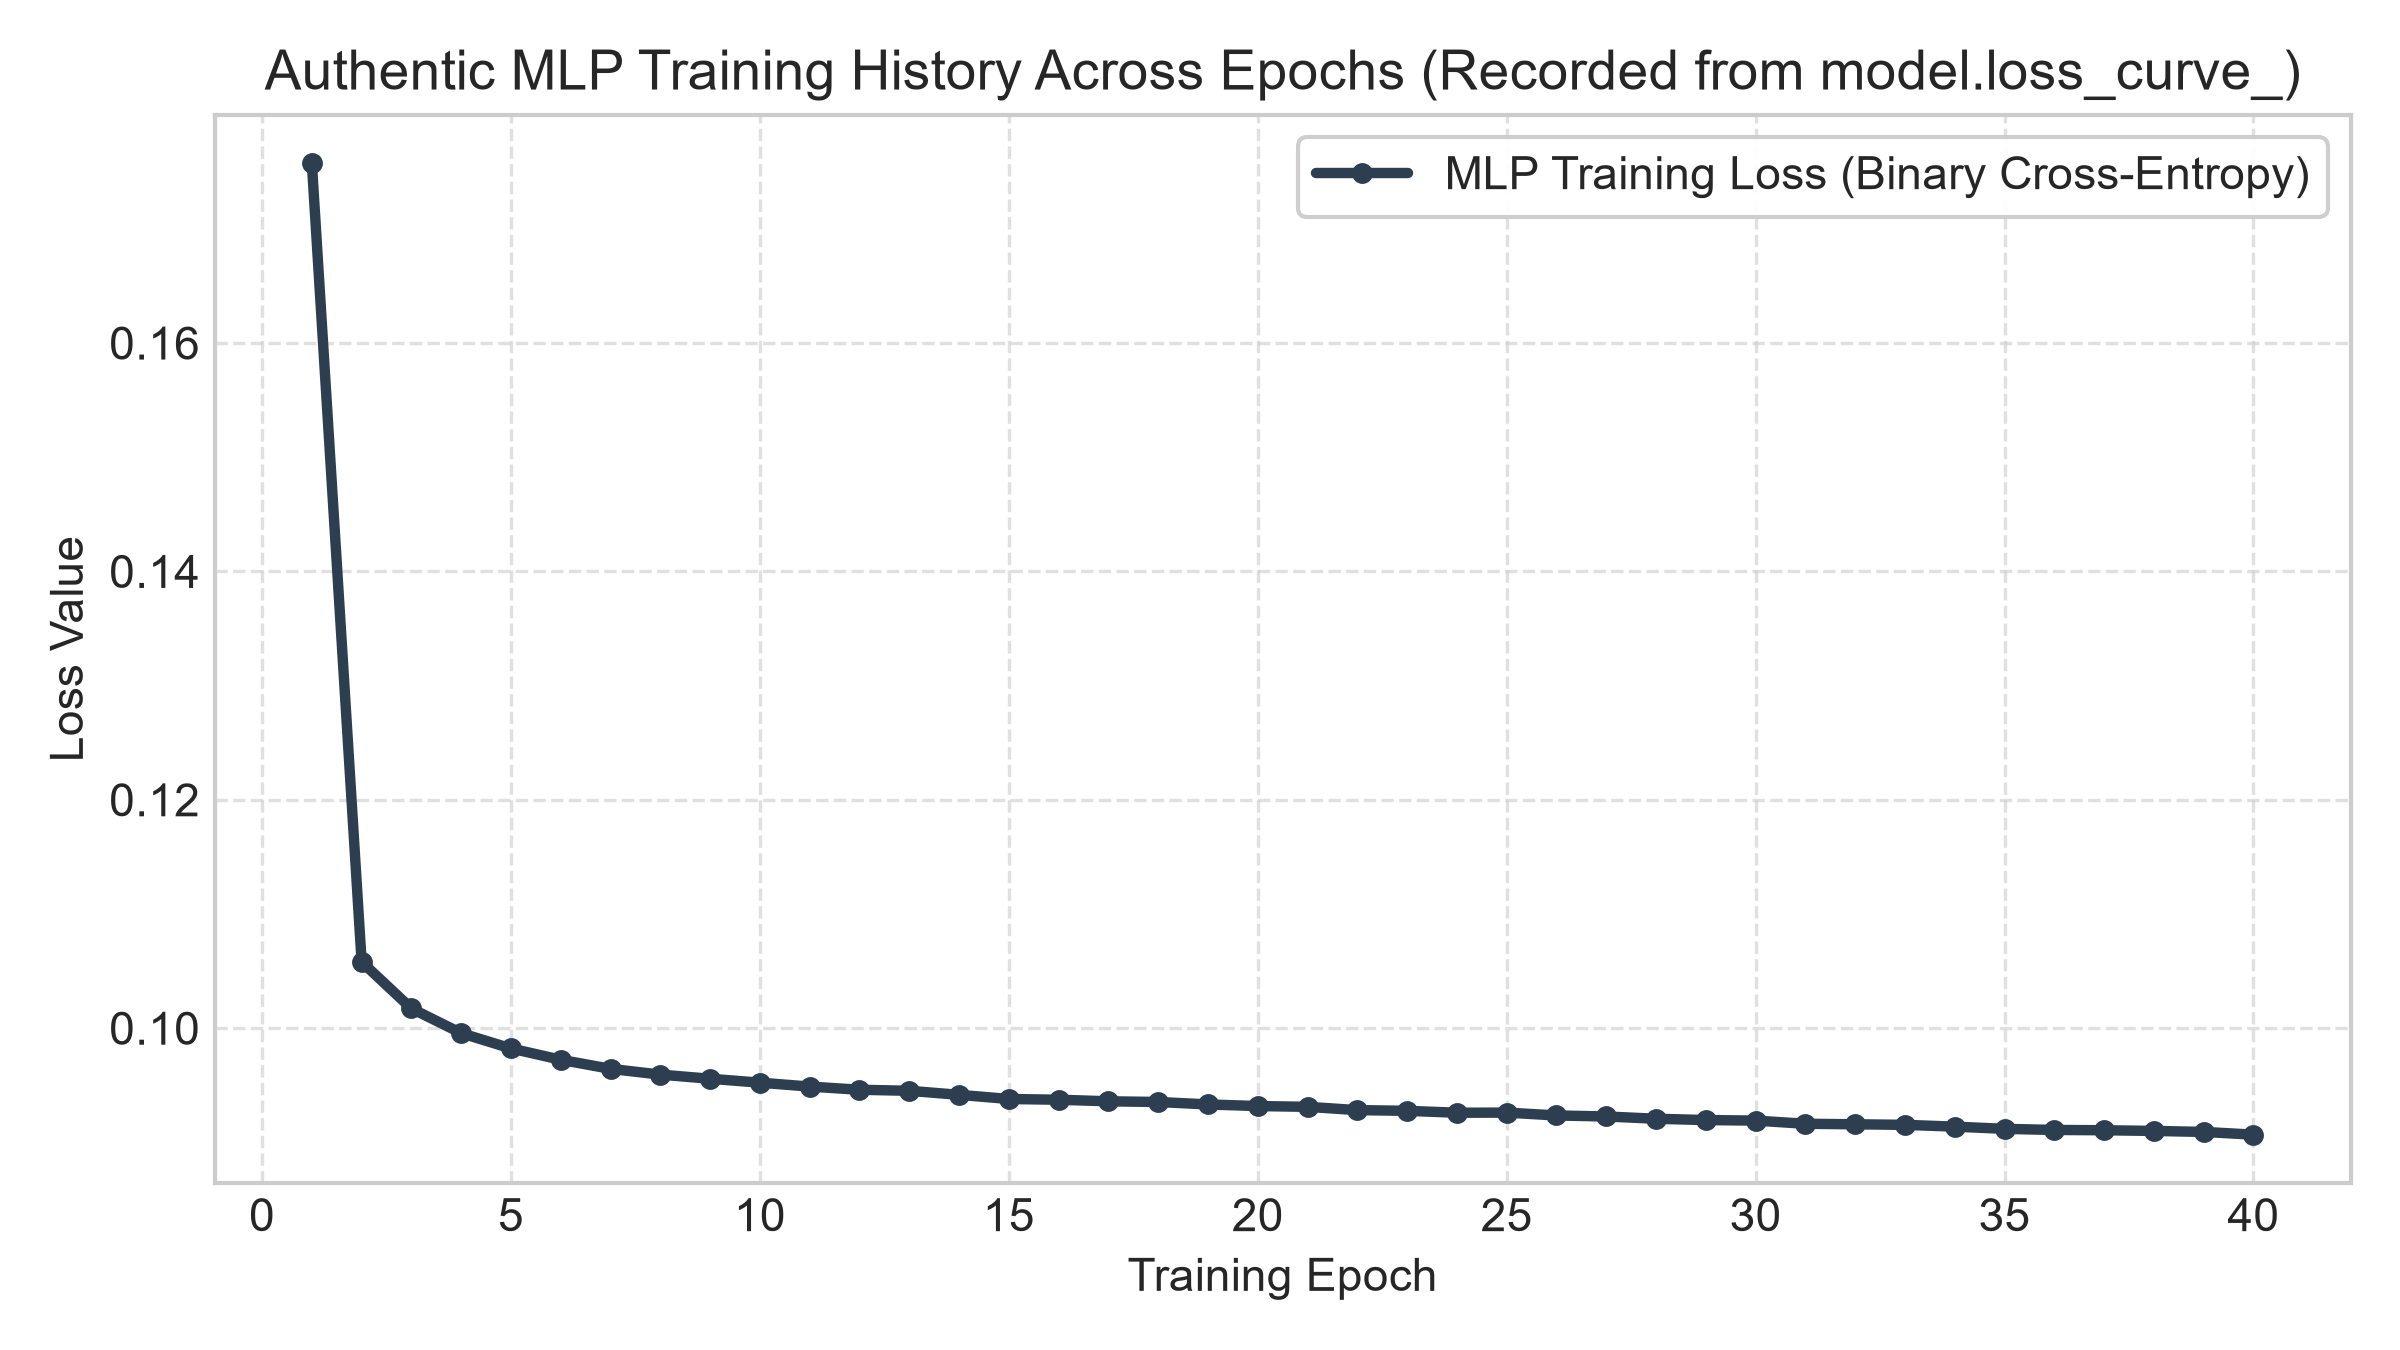

In [5]:
display(Image(filename=str(PROJ_ROOT / "reports" / "figures" / "10_mlp_epoch_loss_curve.png")))
